# 第3章：目标、梯度与稳定性

**教师参考｜全书深化稿**

## 背景与数据
三点直线和单参数二次函数均为人工教学构造，不是观测发现。

## 本次要回答的问题
比较解析梯度与有限差分，计算曲率与学习率上限，区分参数和损失轨迹。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 3: gradients, curvature and feature-scale stability (additional checks)."""
import numpy as np
from common import *

def run():
    x=np.array([1.,2.,3.]); y=np.array([3.,5.,8.]); D=np.column_stack([x,np.ones(3)])
    theta=np.array([1.,0.]);loss=lambda t:np.mean((D@t-y)**2)
    g=2*D.T@(D@theta-y)/len(y)
    eps=1e-6
    numerical=np.array([(loss(theta+eps*np.eye(2)[j])-loss(theta-eps*np.eye(2)[j]))/(2*eps) for j in range(2)])
    assert np.allclose(g,numerical,rtol=1e-7)
    H=2*D.T@D/len(y);eig=np.linalg.eigvalsh(H)
    df=table('ch03_gradient',{'component':['slope','intercept'],'analytic':g,'finite_difference':numerical})
    dump('ch03_curvature',{'hessian':H,'eigenvalues':eig,'constant_step_stability_upper':2/eig[-1]})
    show_result(df)
    rows=[]
    for eta in [.1,.5,.95,1.,1.05]:
        c=0.
        for step in range(21):
            rows.append({'eta':eta,'step':step,'parameter':c,'loss':(c-2)**2})
            c=c-eta*2*(c-2)
    table('ch03_scalar_trace',rows)
    plt.figure(figsize=(6.4,4))
    for eta in [.1,.5,.95,1.05]:
        d=pd.DataFrame(rows);d=d[d.eta==eta]
        plt.plot(d.step,d.parameter,marker='.',label=f'eta={eta}')
    plt.axhline(2,linestyle='--');plt.xlabel('更新次数');plt.ylabel('参数 c');plt.legend();figure('v3_ch03_steps')

In [3]:
result = run()
if result is not None:
    print(result)

component   analytic  finite_difference
    slope -15.333333         -15.333333
intercept  -6.666667          -6.666667


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch03_steps.png


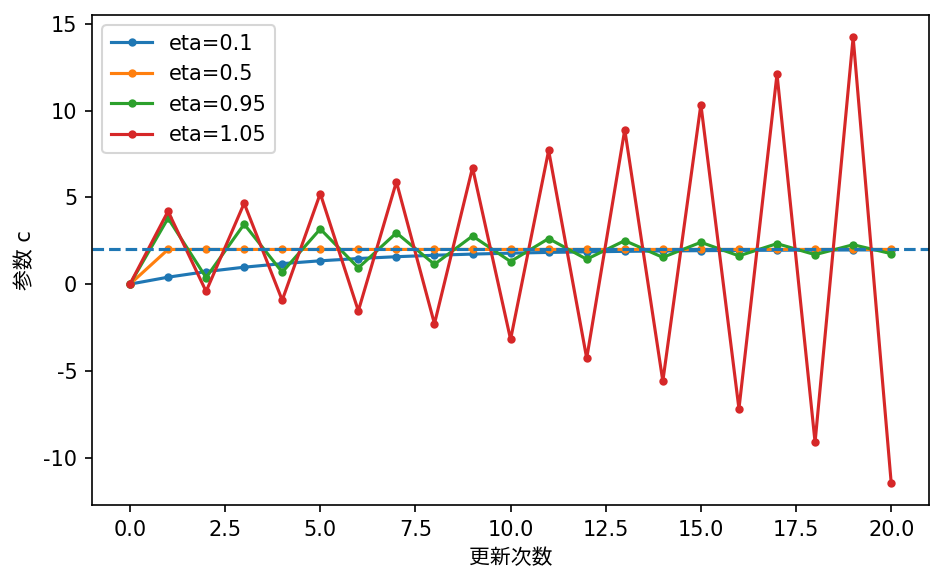

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch03_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 教师解释与核对

二次目标的稳定上限依赖归一化及特征尺度；本例的边界不能直接复制到任意非凸网络。原生详细实验另在chapter03_material。

完整手算解答见`teacher_manual.pdf`。如果结果与这里的参考不同，先检查数据版本、划分、软件环境、目标归一化和随机状态，不要求学生人为调成相同分数。

**评分顺序：**问题与字段角色、数据划分、算法机制、实际结果分析、证据边界。代码能运行但无法说明一项输出的含义，不算完成理解目标。